<div style=" background-color: RGB(0,114,200);" >
<h2 style="margin: auto; padding: 20px 0; color:#fff; text-align: center">PROJET 9 DATA ANALYST</h2>
<h3 style="margin: auto; padding: 20px 0; color:#fff; text-align: center">Produisez une étude de marché avec Python
<h4 style="margin: auto; padding: 20px 0; color:#fff; text-align: center">---- Clustering & Visualisations ----</h4>
</h3>
</div>

<div style="background-color: RGB(0,150,250);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 1 - Importation des librairies et exploration du fichier</h2>
</div>

In [1]:
# Manipulation des dataframes
import pandas as pd
import numpy as np

# Visuels
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px

# Classification ascendante hiérarchique (CAH)
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
from sklearn.metrics import davies_bouldin_score
from math import pi

# Kmeans
from sklearn.cluster import KMeans

# ACP
from sklearn.decomposition import PCA

# Silhouette
from sklearn.metrics import silhouette_score

# Normalisation des données
from sklearn.preprocessing import MinMaxScaler, MaxAbsScaler

# Ignorer les avertissements
import warnings
warnings.filterwarnings('ignore')

+ Le dataset que nous allons utilisé est le résultat du notebook "Analyse exploratoire"
+ df = disponibilite + population + pib + politique


In [2]:
# Importation du dataset
chemin =  "C:/Users/CRFP4534/OneDrive - orange.com/Bureau/Formation CFA - Data Analyst/P9-Produisez une étude de marché avec R ou Python/Data/"

df = pd.read_csv(chemin + 'df_lapoulequichante.csv', sep=',', encoding='utf-8')

In [3]:
# Info sur le dataset
df.info() 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 210 entries, 0 to 209
Data columns (total 14 columns):
 #   Column                                     Non-Null Count  Dtype  
---  ------                                     --------------  -----  
 0   Zone                                       210 non-null    object 
 1   Alimentation pour touristes                210 non-null    float64
 2   Disponibilité alimentaire (Kcal)           210 non-null    float64
 3   Disponibilité intérieure                   210 non-null    float64
 4   Exportations - quantité                    210 non-null    float64
 5   Importations - quantité                    210 non-null    float64
 6   Nourriture                                 210 non-null    float64
 7   Pertes                                     210 non-null    float64
 8   Production                                 210 non-null    float64
 9   Disponibilité alimentaire - Autres (Kcal)  210 non-null    float64
 10  Importations Autres - quan

In [4]:
# Renommer les colonnes pour plus de visibilités dans les graphiques
df = df.rename(columns={
    "Exportations - quantité"  : "Exportations",
    "Importations - quantité"  : "Importations",
})


In [5]:
df.describe()

,Alimentation pour touristes,Disponibilité alimentaire (Kcal),Disponibilité intérieure,Exportations,Importations,Nourriture,Pertes,Production,Disponibilité alimentaire - Autres (Kcal),Importations Autres - quantité,Population totale,PIB par habitant,Stabilité politique
count,210.000000,2.100000e+02,2.100000e+02,2.100000e+02,2.100000e+02,2.100000e+02,210.000000,2.100000e+02,2.100000e+02,2.100000e+02,2.100000e+02,210.000000,210.000000
mean,519.047619,1.098502e+12,7.487730e+05,9.015714e+04,8.923175e+04,7.442222e+05,3133.333333,7.589698e+05,2.558522e+12,2.015270e+05,4.436662e+07,18219.250911,-0.029075
std,5505.389283,4.577546e+12,2.857428e+06,4.370482e+05,2.371624e+05,2.885499e+06,28386.210159,3.009571e+06,1.488468e+13,8.283989e+05,1.739966e+08,28779.923753,0.961257
min,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,4.480000e+03,296.774922,-2.716132
25%,0.000000,1.638107e+10,1.258333e+04,0.000000e+00,1.333333e+03,1.183333e+04,0.000000,1.666667e+03,2.846950e+10,2.000000e+03,1.224474e+06,2291.745019,-0.528671
50%,0.000000,1.015792e+11,7.483333e+04,0.000000e+00,1.416667e+04,7.466667e+04,0.000000,5.100000e+04,2.593628e+11,1.133333e+04,6.984815e+06,6739.691419,0.000000
75%,0.000000,4.055247e+11,3.094167e+05,8.416667e+03,7.091667e+04,2.894167e+05,0.000000,2.352500e+05,8.766187e+11,6.841667e+04,2.674791e+07,21209.005087,0.807663
max,79333.333333,4.283474e+13,2.531067e+07,4.322667e+06,2.114000e+06,2.568567e+07,399666.666667,2.440300e+07,1.520650e+14,8.402667e+06,1.457629e+09,219401.697822,1.785995


In [6]:
# Afficher les premières lignes du dataset
df.head()

,Zone,Alimentation pour touristes,Disponibilité alimentaire (Kcal),Disponibilité intérieure,Exportations,Importations,Nourriture,Pertes,Production,Disponibilité alimentaire - Autres (Kcal),Importations Autres - quantité,Population totale,PIB par habitant,Stabilité politique
0,Afghanistan,0.0,7.381615e+10,5.366667e+04,0.000000,25333.333333,5.366667e+04,0.0,2.833333e+04,5.140795e+11,5.666667e+03,3.988274e+07,411.827311,-2.588784
1,Afrique du Sud,0.0,3.248965e+12,2.361000e+06,48666.666667,367000.000000,2.361000e+06,0.0,1.920667e+06,3.274602e+12,2.966667e+04,6.148113e+07,6531.053355,-0.561745
2,Albanie,0.0,6.516039e+10,4.700000e+04,0.000000,32000.000000,4.700000e+04,0.0,1.533333e+04,1.552584e+11,1.600000e+04,2.849732e+06,6075.098246,0.130415
3,Algérie,0.0,3.696802e+11,2.683333e+05,1000.000000,0.000000,2.683333e+05,0.0,2.690000e+05,1.124005e+12,1.766667e+04,4.476019e+07,3776.133349,-0.830310
4,Allemagne,0.0,1.933838e+12,1.531000e+06,608333.333333,774666.666667,1.438667e+06,0.0,1.541667e+06,7.506617e+12,1.628333e+06,8.380401e+07,48950.854257,0.666443


<div style="background-color: RGB(0,150,250);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 2 - Clustering & Visualisations</h2>
</div>

<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">2.1 - Classification Ascendante Hiérarchique (CAH)</h3>
</div>

In [7]:
# Initialisation du dataset
df_cah = df.copy()

# Dendogramme

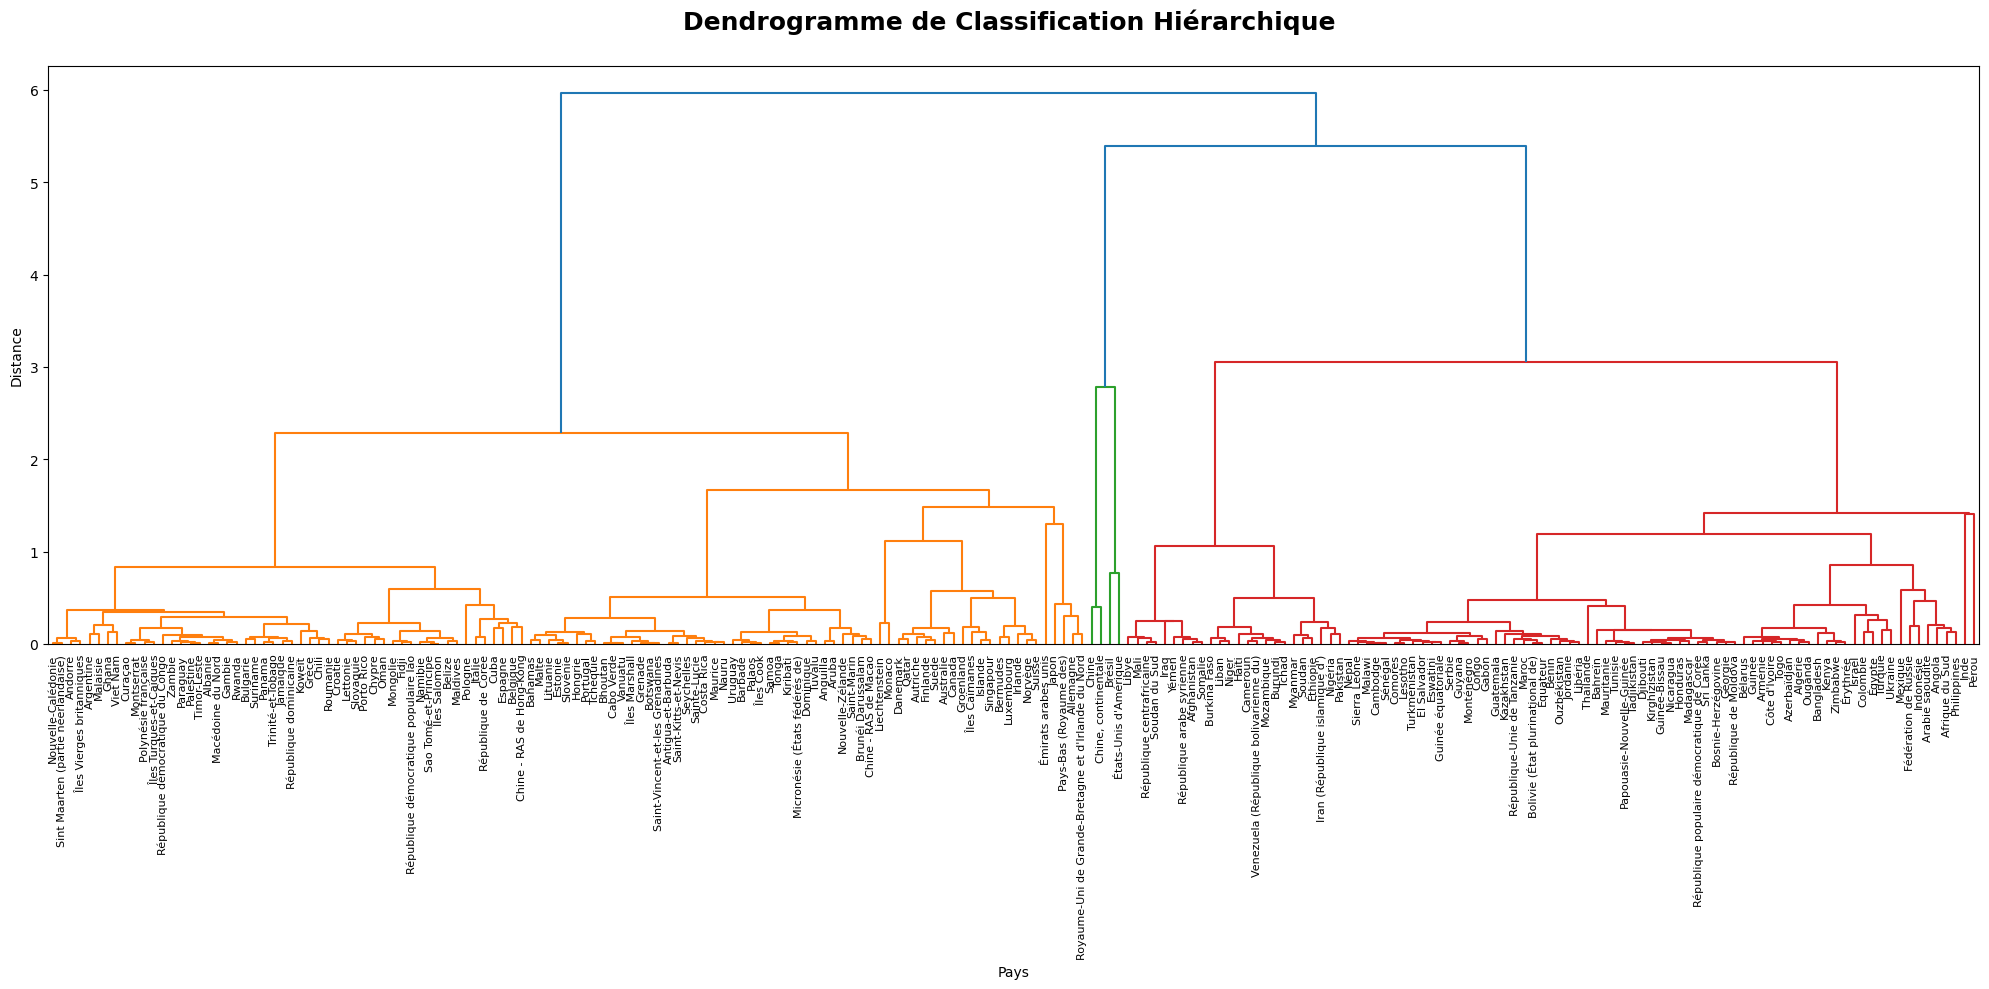

In [8]:
# Normalisation des données
scaler = MaxAbsScaler() 
cah_scaled = scaler.fit_transform(df_cah.select_dtypes(include=['float64', 'int64']))

# Création de la matrice de linkage
Z = linkage(cah_scaled, method='ward')

# Visualisation du dendrogramme
noms = df_cah['Zone'].values  # Récupérer le nom des pays pour les étiquettes
fig, ax = plt.subplots(1, 1, figsize=(20, 10))  # Augmenter la hauteur pour plus de lisibilité
ax.set_title("Dendrogramme de Classification Hiérarchique \n", fontsize=18, fontweight='bold')
ax.set_xlabel("Pays", fontsize=10)
ax.set_ylabel("Distance", fontsize=10)
ax.tick_params(axis='x', which='major', labelsize=8, rotation=90)  # Rotation des étiquettes
dendrogram(Z, ax=ax, labels=noms, leaf_font_size=8)  # Ajuster la taille des étiquettes
plt.tight_layout()  # Ajuster automatiquement les marges
plt.show()

+ A première vue, il y a 5 clusters qui se dessine mais, nous allons le confirmer mathématiquement avec le calcul de l'indice de Davies-Bouldin.

# Identification du nombre de cluster optimal 

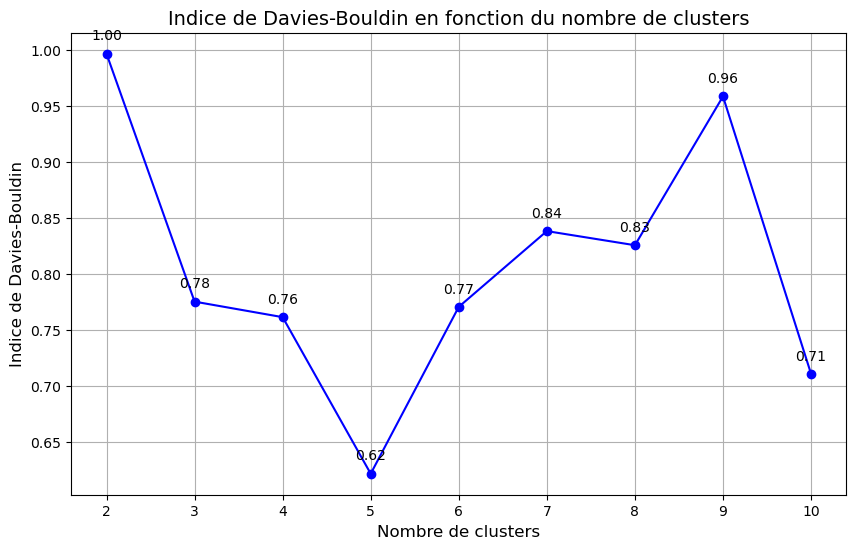

In [9]:
# Calcul de l'indice de Davies-Bouldin pour différents nombres de clusters
dbi_scores = []
cluster_range = range(2, 11)  # Tester de 2 à 10 clusters

for k in cluster_range:
    labels = fcluster(Z, t=k, criterion='maxclust')
    dbi = davies_bouldin_score(cah_scaled, labels)
    dbi_scores.append(dbi)

# Tracer la courbe
plt.figure(figsize=(10, 6))
plt.plot(cluster_range, dbi_scores, marker='o', linestyle='-', color='b')

# Ajouter des infobulles pour chaque point
for i, dbi in enumerate(dbi_scores):
    plt.annotate(f"{dbi:.2f}", (cluster_range[i], dbi), textcoords="offset points", xytext=(0, 10), ha='center')

# Ajouter les titres et les axes
plt.title("Indice de Davies-Bouldin en fonction du nombre de clusters", fontsize=14)
plt.xlabel("Nombre de clusters", fontsize=12)
plt.ylabel("Indice de Davies-Bouldin", fontsize=12)
plt.xticks(cluster_range)
plt.grid(True)
plt.show() 

+ D'après la courbe d'évolution de l'indice de Davies-Bouldin, nous pouvons confirmer que le nombre de cluster optimal est 5 parce que c'est là où l'indice est le plus faible.

# Fixation du nombre de cluster

In [10]:
# Fixer le nombre de clusters  
n_clusters = 5
labels = fcluster(Z, t=n_clusters, criterion='maxclust')

# Ajouter les labels des clusters au DataFrame
df_cah['Cluster'] = labels

# Lister les pays dans chaque cluster
clusters = {}
for cluster_id in range(1, n_clusters + 1):
    clusters[cluster_id] = df_cah[df_cah['Cluster'] == cluster_id]['Zone'].tolist()

# Afficher les pays par cluster
for cluster_id, countries in clusters.items():
    print(f"Cluster {cluster_id}:")
    print(", ".join(countries))
    print()

Cluster 1:
Albanie, Allemagne, Andorre, Anguilla, Antigua-et-Barbuda, Argentine, Aruba, Australie, Autriche, Bahamas, Barbade, Belgique, Belize, Bermudes, Bhoutan, Botswana, Brunéi Darussalam, Bulgarie, Cabo Verde, Canada, Chili, Chine - RAS de Hong-Kong, Chine - RAS de Macao, Chypre, Costa Rica, Croatie, Cuba, Curaçao, Danemark, Dominique, Espagne, Estonie, Fidji, Finlande, Gambie, Ghana, Grenade, Groenland, Grèce, Hongrie, Irlande, Islande, Italie, Jamaïque, Japon, Kiribati, Koweït, Lettonie, Liechtenstein, Lituanie, Luxembourg, Macédoine du Nord, Malaisie, Maldives, Malte, Maurice, Micronésie (États fédérés de), Monaco, Mongolie, Montserrat, Namibie, Nauru, Norvège, Nouvelle-Calédonie, Nouvelle-Zélande, Oman, Palaos, Palestine, Panama, Paraguay, Pays-Bas (Royaume des), Pologne, Polynésie française, Porto Rico, Portugal, Qatar, Roumanie, Royaume-Uni de Grande-Bretagne et d'Irlande du Nord, Rwanda, République de Corée, République dominicaine, République démocratique du Congo, Républiq

+ Certains clusters sont constitués de 2 pays seulement. D'un point de vue fonctionnelle, il serait mieux de regrouper ces derniers afin d'optimiser notre ciblage. Pour ce faire, nous allons tester le nombre de cluster = 4. 

In [11]:
# Fixer le nombre de clusters à 4 
n_clusters = 4
labels = fcluster(Z, t=n_clusters, criterion='maxclust')

# Ajouter les labels des clusters au DataFrame
df_cah['Cluster'] = labels

# Lister les pays dans chaque cluster
clusters = {}
for cluster_id in range(1, n_clusters + 1):
    clusters[cluster_id] = df_cah[df_cah['Cluster'] == cluster_id]['Zone'].tolist()

# Afficher les pays par cluster
for cluster_id, countries in clusters.items():
    print(f"Cluster {cluster_id}:")
    print(", ".join(countries))
    print()

Cluster 1:
Albanie, Allemagne, Andorre, Anguilla, Antigua-et-Barbuda, Argentine, Aruba, Australie, Autriche, Bahamas, Barbade, Belgique, Belize, Bermudes, Bhoutan, Botswana, Brunéi Darussalam, Bulgarie, Cabo Verde, Canada, Chili, Chine - RAS de Hong-Kong, Chine - RAS de Macao, Chypre, Costa Rica, Croatie, Cuba, Curaçao, Danemark, Dominique, Espagne, Estonie, Fidji, Finlande, Gambie, Ghana, Grenade, Groenland, Grèce, Hongrie, Irlande, Islande, Italie, Jamaïque, Japon, Kiribati, Koweït, Lettonie, Liechtenstein, Lituanie, Luxembourg, Macédoine du Nord, Malaisie, Maldives, Malte, Maurice, Micronésie (États fédérés de), Monaco, Mongolie, Montserrat, Namibie, Nauru, Norvège, Nouvelle-Calédonie, Nouvelle-Zélande, Oman, Palaos, Palestine, Panama, Paraguay, Pays-Bas (Royaume des), Pologne, Polynésie française, Porto Rico, Portugal, Qatar, Roumanie, Royaume-Uni de Grande-Bretagne et d'Irlande du Nord, Rwanda, République de Corée, République dominicaine, République démocratique du Congo, Républiq

# Caractéristiques des clusters 

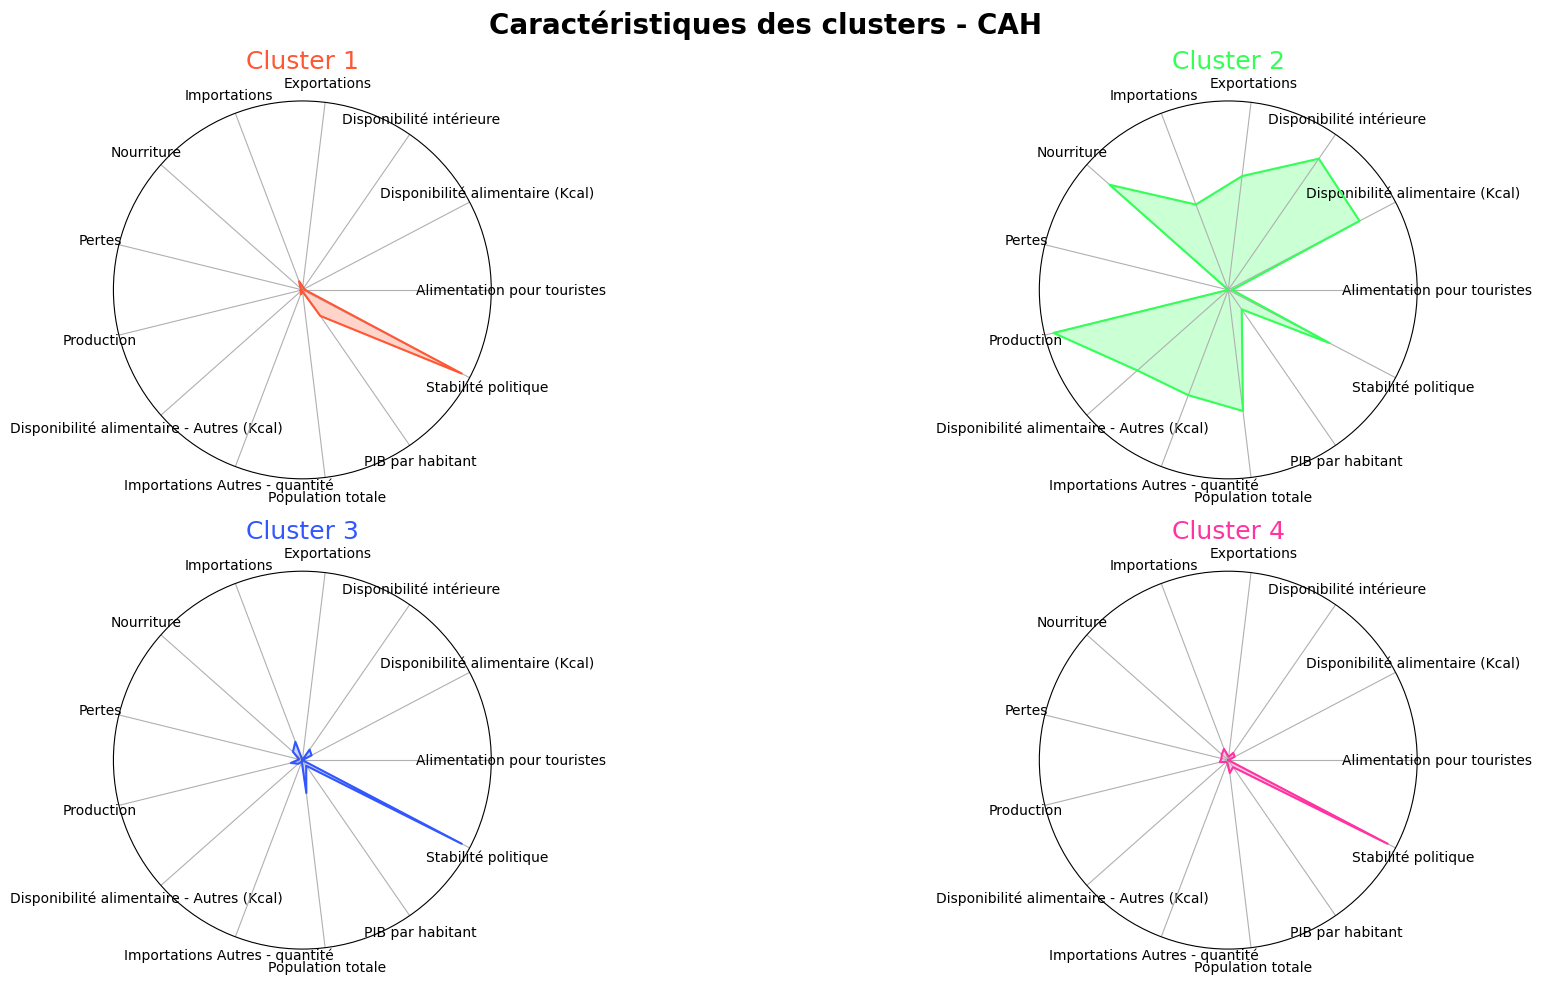

In [12]:
# Normalisation des colonnes numériques avec MinMaxScaler
scaler = MinMaxScaler()
numeric_columns = df_cah.select_dtypes(include=['float64', 'int64']).columns  # Sélection des colonnes numériques
df_cah[numeric_columns] = scaler.fit_transform(df_cah[numeric_columns])

# Préparer les données pour le radar plot
categories = numeric_columns  # Utiliser les colonnes numériques normalisées
num_vars = len(categories)
angles = [n / float(num_vars) * 2 * pi for n in range(num_vars)]
angles += angles[:1]

# Définir une liste de couleurs pour les clusters
colors = ['#FF5733', '#33FF57', '#3357FF', '#FF33A1']

# Créer les radar plots pour chaque cluster
fig, axes = plt.subplots(2, 2, figsize=(20, 10), subplot_kw=dict(polar=True))
axes = axes.flatten()

for i in range(4):  # 4  clusters
    cluster_data = df_cah[df_cah['Cluster'] == i + 1][categories].mean().values  # Moyenne des valeurs par cluster
    cluster_data = np.append(cluster_data, cluster_data[0])  # Boucler les valeurs pour le radar plot
    ax = axes[i]
    ax.fill(angles, cluster_data, alpha=0.25, color=colors[i], label=f'Cluster {i + 1}')
    ax.plot(angles, cluster_data, color=colors[i], label=f'Cluster {i + 1}')
    ax.set_yticks([])
    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(categories, fontsize= 10)
    ax.set_title(f'Cluster {i + 1}', size=18, color=colors[i])
    
# Ajouter un titre global au graphique
fig.suptitle("Caractéristiques des clusters - CAH", fontsize=20, fontweight='bold')

plt.tight_layout()
plt.show()

- Supprimons la colonne 'Stabilité politique' pour mieux caractériser les clusters

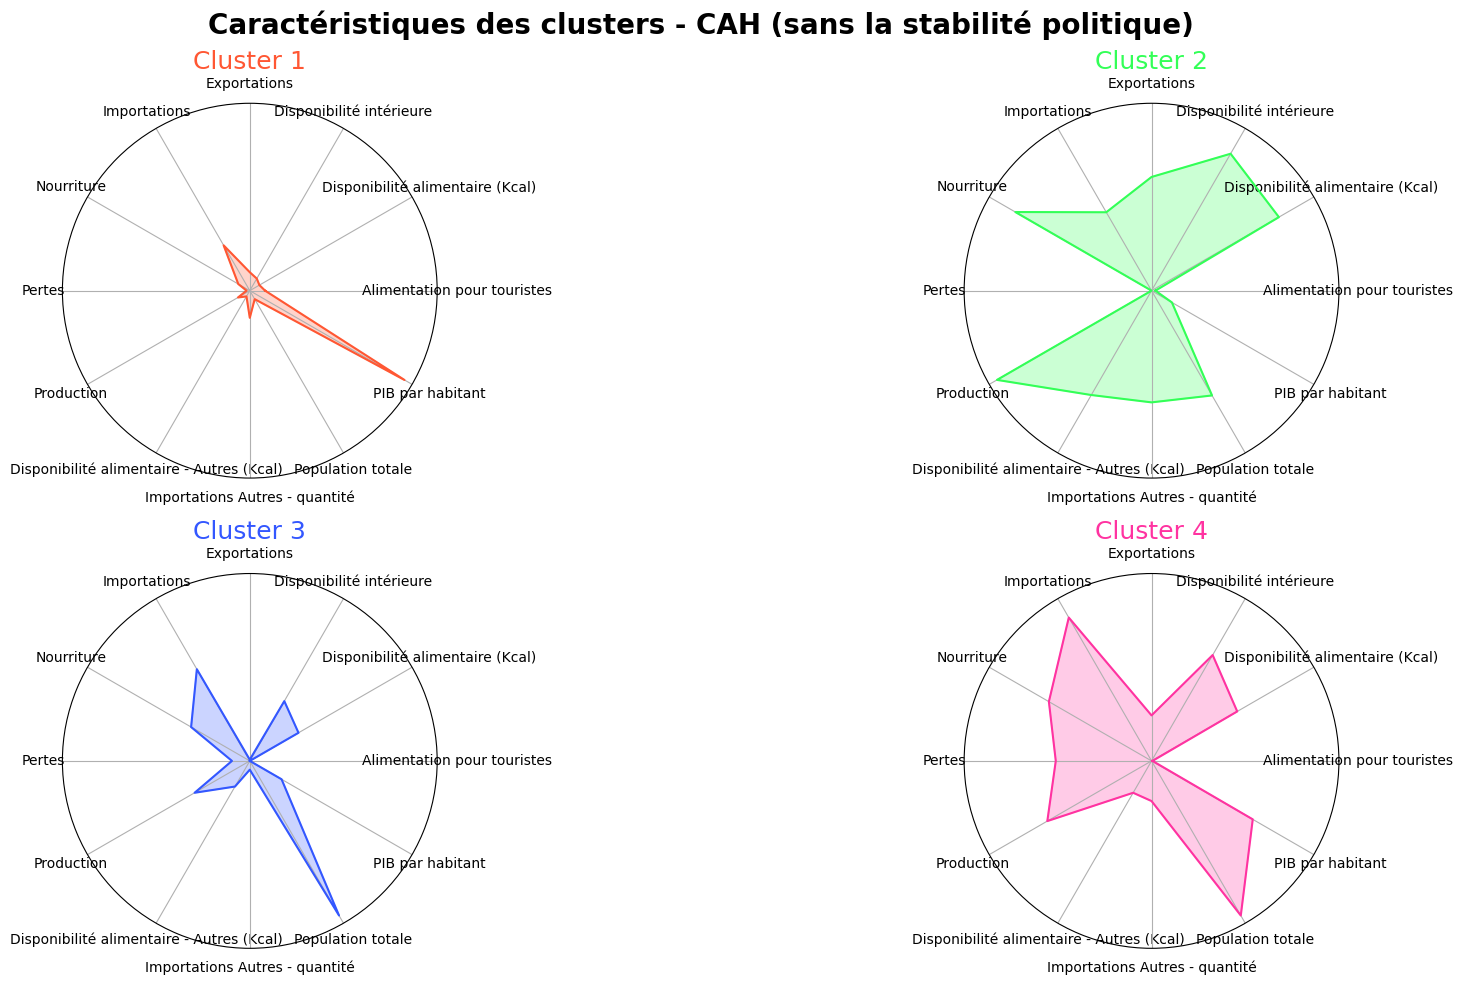

In [13]:
# Supprimons la colonne 'Stabilité politique'
df_cah2 = df_cah.drop(columns=['Stabilité politique'])

# Normalisation des colonnes numériques avec MinMaxScaler
scaler = MinMaxScaler()
numeric_columns = df_cah2.select_dtypes(include=['float64', 'int64']).columns  # Sélection des colonnes numériques
df_cah2[numeric_columns] = scaler.fit_transform(df_cah2[numeric_columns])

# Préparer les données pour le radar plot
categories = numeric_columns  # Utiliser les colonnes numériques normalisées
num_vars = len(categories)
angles = [n / float(num_vars) * 2 * pi for n in range(num_vars)]
angles += angles[:1]

# Définir une liste de couleurs pour les clusters
colors = ['#FF5733', '#33FF57', '#3357FF', '#FF33A1']

# Créer les radar plots pour chaque cluster
fig, axes = plt.subplots(2, 2, figsize=(20, 10), subplot_kw=dict(polar=True))
axes = axes.flatten()

for i in range(4):  # 4  clusters
    cluster_data = df_cah2[df_cah2['Cluster'] == i + 1][categories].mean().values  # Moyenne des valeurs par cluster
    cluster_data = np.append(cluster_data, cluster_data[0])  # Boucler les valeurs pour le radar plot
    ax = axes[i]
    ax.fill(angles, cluster_data, alpha=0.25, color=colors[i], label=f'Cluster {i + 1}')
    ax.plot(angles, cluster_data, color=colors[i], label=f'Cluster {i + 1}')
    ax.set_yticks([])
    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(categories, fontsize= 10)
    ax.set_title(f'Cluster {i + 1}', size=18, color=colors[i])

# Ajouter un titre global au graphique
fig.suptitle("Caractéristiques des clusters - CAH (sans la stabilité politique)", fontsize=20, fontweight='bold')

plt.tight_layout()
plt.show()

+ Caractéristiques des clusters :
  + Cluster 1 : Pays caractérisés par son index de stabilité politique, un PIB par habitant fort et un peu d'importation ;
  + Cluster 2 : Pays producteurs avec une disponibilité alimentaire élevée, un PIB par habitant moyen et une population élevée ; 
  + Cluster 3 : Pays importateurs mais pas assez producteurs avec une population élevée ;
  + Cluster 4 : Pays importateurs avec une population élevée.

+ Proposition : Cibler les pays dans le Cluster 1 avec un PIB par habitant fort et où le marché de l'importation de volaille n'est pas encore saturé.

<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">2.2 - Méthode de k-means</h3>
</div>

In [14]:
# Initialisation du dataset
df_kmeans = df.copy()

# Identification du nombre de cluster optimal

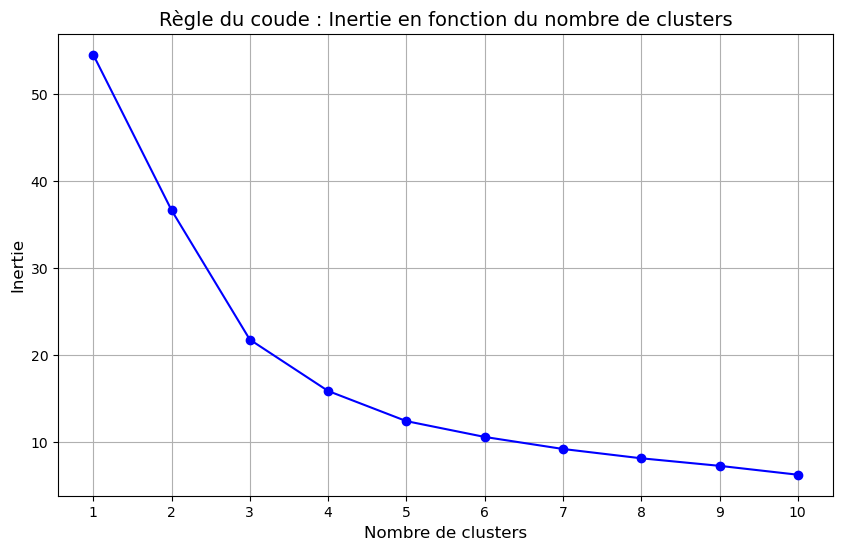

In [15]:
# Règle du coude
# Normalisation des données
scaler = MaxAbsScaler()
kmeans_scaled = scaler.fit_transform(df_kmeans.select_dtypes(include=['float64', 'int64']))

# Calcul de l'inertie pour différents nombres de clusters
inertia = []
cluster_range = range(1, 11)  # Tester de 1 à 10 clusters

for k in cluster_range:
    kmeans = KMeans(n_clusters=k, random_state=0)
    kmeans.fit(kmeans_scaled) #scaled
    inertia.append(kmeans.inertia_)

# Tracer la courbe de la règle du coude
plt.figure(figsize=(10, 6))
plt.plot(cluster_range, inertia, marker='o', linestyle='-', color='b')
plt.title("Règle du coude : Inertie en fonction du nombre de clusters", fontsize=14)
plt.xlabel("Nombre de clusters", fontsize=12)
plt.ylabel("Inertie", fontsize=12)
plt.xticks(cluster_range)
plt.grid(True)
plt.show()

+ D'après la courbe ci-dessus, nous allons fixer le nombre de cluster à 4 car c'est là que nous observons un point d'inflexion.

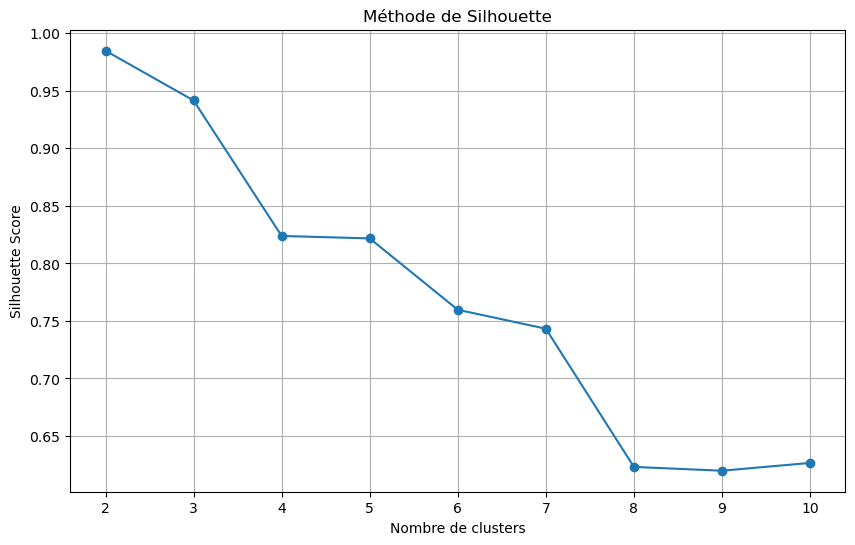

In [16]:
# Sélectionner les colonnes numériques à partir de df_kmeans
numeric_data = df_kmeans.select_dtypes(include=['float64', 'int64'])

# Itérer sur différentes valeurs de k (à partir de 2 car la silhouette nécessite au moins 2 clusters)
silhouette_scores = []
k_values = range(2, 11)

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=0)
    labels = kmeans.fit_predict(numeric_data)
    score = silhouette_score(numeric_data, labels)
    silhouette_scores.append(score)

# Visualiser l'évolution du score de silhouette
plt.figure(figsize=(10, 6))
plt.plot(list(k_values), silhouette_scores, marker='o', linestyle='-')
plt.xlabel("Nombre de clusters")
plt.ylabel("Silhouette Score")
plt.title("Méthode de Silhouette")
plt.grid(True)
plt.show()

+ D'après la courbe et en cohérence avec la règle du coude, le nombre de cluster optimal est "4" sinon les clusters seront constitués de nombreux pays, ce qui rend le ciblage difficile.

# Fixer le nombre de cluster

In [17]:
# Fixer le nombre de clusters 
n= 4

# Appliquer KMeans
kmeans = KMeans(n_clusters=n,random_state=0)
df_kmeans['Cluster'] = kmeans.fit_predict(df_kmeans.select_dtypes(include=['float64', 'int64'])) + 1 

# Lister les pays dans chaque cluster
clusters = {}
for cluster_id in range(1, n + 1):  
    clusters[cluster_id] = df_kmeans[df_kmeans['Cluster'] == cluster_id]['Zone'].tolist()

# Afficher les pays par cluster
for cluster_id, countries in clusters.items():
    print(f"Cluster {cluster_id}:")
    print(", ".join(countries))
    print()

Cluster 1:
Afghanistan, Albanie, Algérie, Andorre, Angola, Anguilla, Antigua-et-Barbuda, Arabie saoudite, Arménie, Aruba, Australie, Autriche, Azerbaïdjan, Bahamas, Bahreïn, Bangladesh, Barbade, Belgique, Belize, Bermudes, Bhoutan, Bolivie (État plurinational de), Bosnie-Herzégovine, Botswana, Brunéi Darussalam, Bulgarie, Burkina Faso, Burundi, Bélarus, Bénin, Cabo Verde, Cambodge, Cameroun, Chili, Chine - RAS de Hong-Kong, Chine - RAS de Macao, Chypre, Comores, Congo, Costa Rica, Croatie, Cuba, Curaçao, Côte d'Ivoire, Danemark, Djibouti, Dominique, El Salvador, Estonie, Eswatini, Fidji, Finlande, Gabon, Gambie, Ghana, Grenade, Groenland, Grèce, Guatemala, Guinée, Guinée équatoriale, Guinée-Bissau, Guyana, Géorgie, Haïti, Honduras, Hongrie, Iran (République islamique d'), Iraq, Irlande, Islande, Israël, Jamaïque, Jordanie, Kazakhstan, Kenya, Kirghizistan, Kiribati, Koweït, Lesotho, Lettonie, Liban, Libye, Libéria, Liechtenstein, Lituanie, Luxembourg, Macédoine du Nord, Madagascar, Mala

# Caractériser les clusters

+ En analysant les centroides

In [18]:
# Centroides des clusters
centers = kmeans.cluster_centers_  
centroids_df = pd.DataFrame(centers, columns=df_kmeans.select_dtypes(include=['float64', 'int64']).columns)

# Définir le nom de chaque cluster
cluster_names = {i: f"Cluster {i+1}" for i in range(centers.shape[0])}
centroids_df['Cluster_Name'] = centroids_df.index.map(cluster_names)

# Réorganiser les colonnes pour mettre le nom du cluster en première colonne
cols = ['Cluster_Name'] + [col for col in centroids_df.columns if col != 'Cluster_Name']
centroids_df = centroids_df[cols]

print("Centroïdes des clusters :")
centroids_df

Centroïdes des clusters :


,Cluster_Name,Alimentation pour touristes,Disponibilité alimentaire (Kcal),Disponibilité intérieure,Exportations,Importations,Nourriture,Pertes,Production,Disponibilité alimentaire - Autres (Kcal),Importations Autres - quantité,Population totale,PIB par habitant,Stabilité politique
0,Cluster 1,549.019608,2.475153e+11,1.826881e+05,2.804635e+04,4.861141e+04,1.764296e+05,3062.388592,1.646506e+05,4.143153e+11,5.810339e+04,1.449165e+07,17956.514286,-0.012856
1,Cluster 2,3000.000000,4.184426e+13,2.462183e+07,6.503333e+05,1.782000e+06,2.499983e+07,0.000000,2.400317e+07,1.503793e+14,7.852500e+06,1.441768e+09,11901.594686,-0.240311
2,Cluster 3,0.000000,1.947633e+13,1.433217e+07,4.133167e+06,8.083333e+04,1.432050e+07,0.000000,1.838617e+07,2.797350e+13,1.283667e+06,2.749415e+08,38853.917064,-0.215905
3,Cluster 4,17.543860,3.250471e+12,2.377456e+06,2.169123e+05,3.117193e+05,2.350193e+06,4491.228070,2.306070e+06,5.426681e+12,6.938421e+05,1.670333e+08,19298.078759,-0.146809


+ Caractéristiques des clusters :
  + Cluster 1 : Pays à faible disponibilité alimentaire et à faible production avec un PIB par habitant moyen ;
  + Cluster 2 : Pays importateurs avec une population élevée ;
  + Cluster 3 : Pays exportateurs avec un PIB par habitant fort ;
  + Cluster 4 : Pays à disponibilité alimentaire moyenne avec PIB par habitant fort.

+ Avec un radarplot

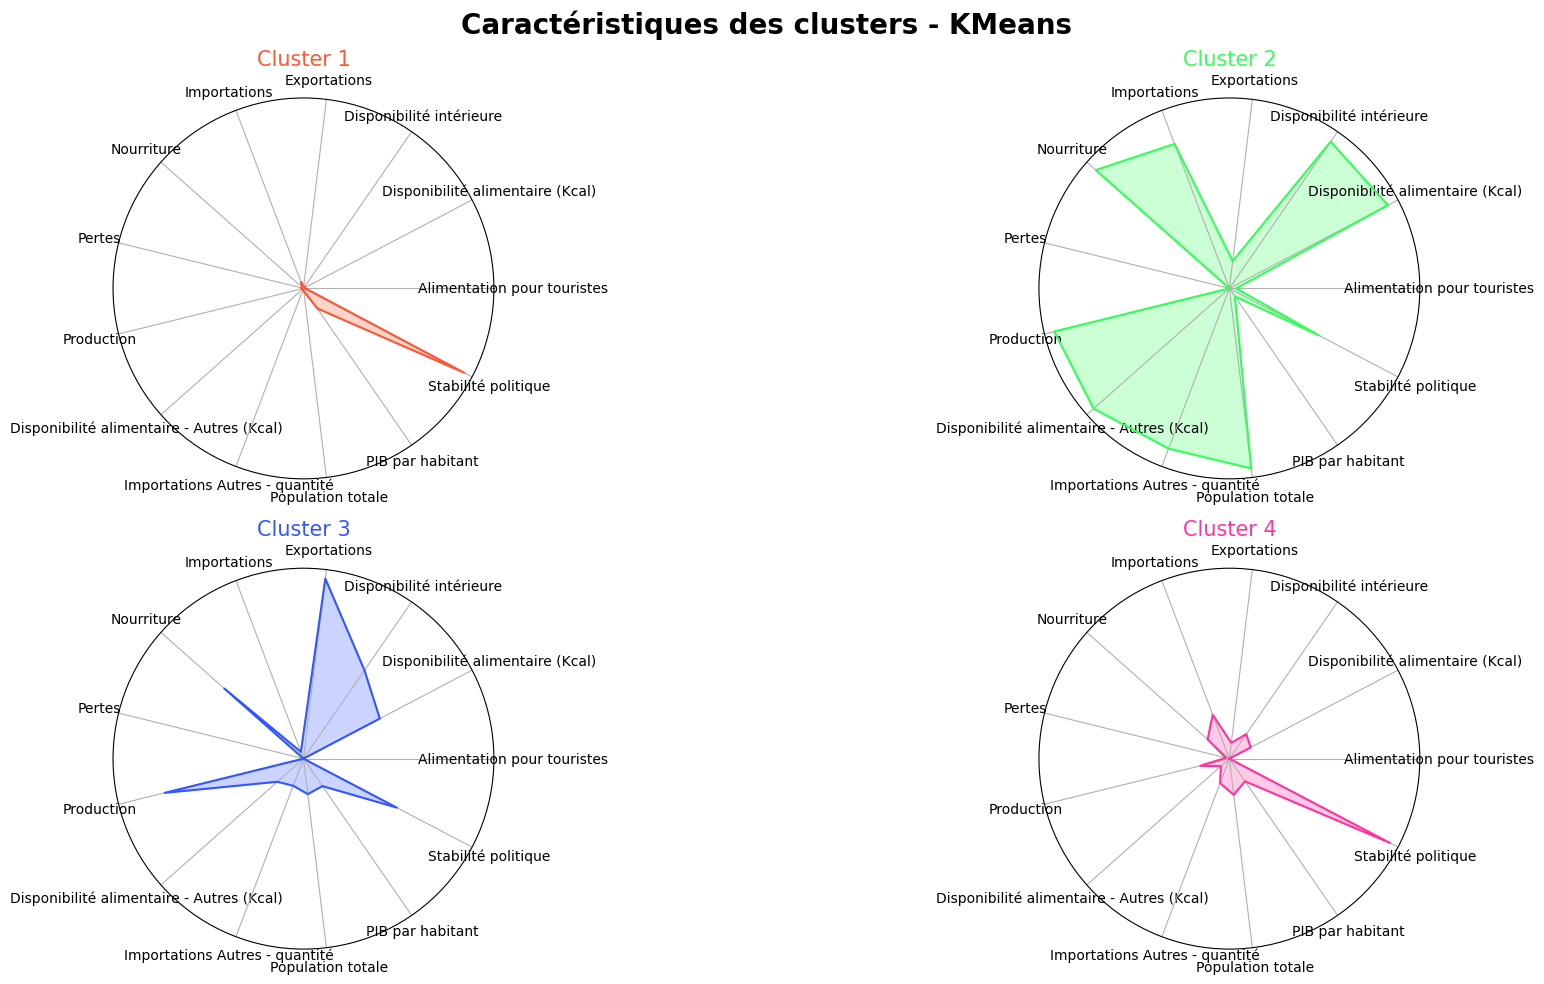

In [19]:
# Normalisation des colonnes numériques
scaler = MinMaxScaler()
numeric_columns = df_kmeans.select_dtypes(include=['float64', 'int64']).columns
df_kmeans[numeric_columns] = scaler.fit_transform(df_kmeans[numeric_columns])

# Préparer les données pour le radar plot
categories = numeric_columns
num_vars = len(categories)
angles = [n / float(num_vars) * 2 * pi for n in range(num_vars)]
angles += angles[:1]

# Définir une liste de couleurs pour les clusters
colors = ['#FF5733', '#33FF57', '#3357FF', '#FF33A1']

# Créer un radar plot pour chaque cluster
fig, axes = plt.subplots(2, 2, figsize=(20, 10), subplot_kw=dict(polar=True))  # Ajuster selon le nombre de clusters
axes = axes.flatten()

for i, cluster_id in enumerate(sorted(df_kmeans['Cluster'].unique())):  # Utiliser df_kmeans['Cluster']
    cluster_data = df_kmeans[df_kmeans['Cluster'] == cluster_id][categories].mean().values  # Moyenne des valeurs par cluster
    cluster_data = np.append(cluster_data, cluster_data[0])  # Boucler les valeurs pour le radar plot
    ax = axes[i]
    ax.fill(angles, cluster_data, alpha=0.25, color=colors[i % len(colors)], label=f'Cluster {cluster_id}')
    ax.plot(angles, cluster_data, color=colors[i % len(colors)], label=f'Cluster {cluster_id}')
    ax.set_yticks([])
    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(categories, fontsize=10)
    ax.set_title(f'Cluster {cluster_id}', size=15, color=colors[i % len(colors)])

# Ajouter un titre global au graphique
fig.suptitle("Caractéristiques des clusters - KMeans", fontsize=20, fontweight='bold')

plt.tight_layout()
plt.show()

- Supprimons la colonne 'Stabilité politique' pour mieux caractériser les clusters

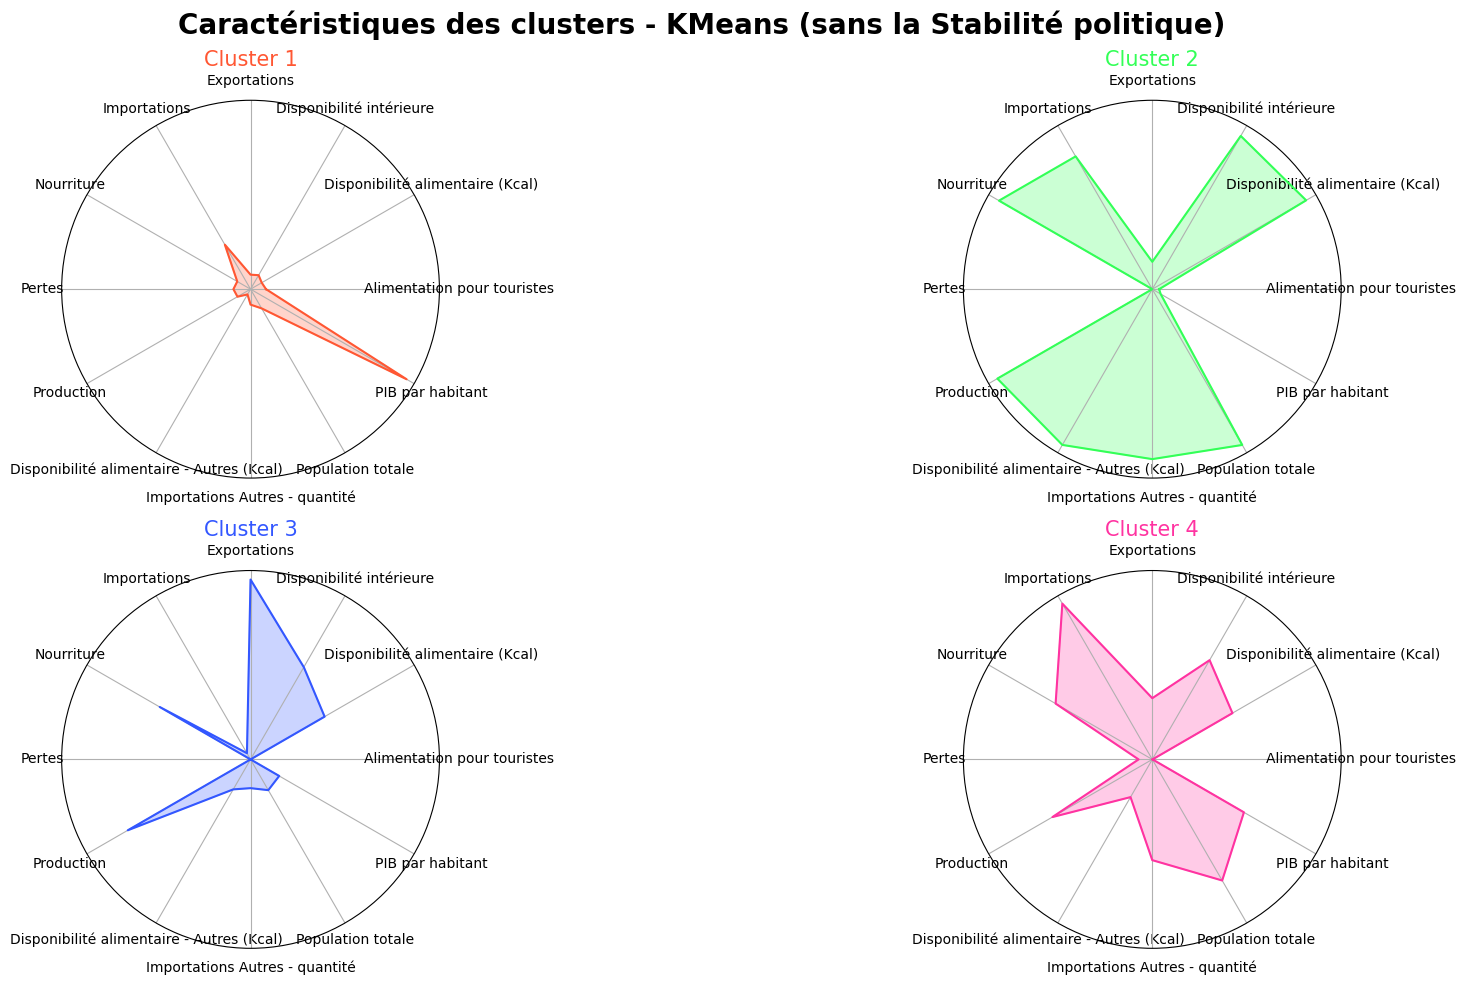

In [20]:
# Supprimons la colonne 'Stabilité politique'
df_kmeans2 = df_kmeans.drop(columns=['Stabilité politique'])

# Normalisation des colonnes numériques
scaler = MinMaxScaler()
numeric_columns = df_kmeans2.select_dtypes(include=['float64', 'int64']).columns
df_kmeans2[numeric_columns] = scaler.fit_transform(df_kmeans2[numeric_columns])

# Préparer les données pour le radar plot
categories = numeric_columns
num_vars = len(categories)
angles = [n / float(num_vars) * 2 * pi for n in range(num_vars)]
angles += angles[:1]

# Définir une liste de couleurs pour les clusters
colors = ['#FF5733', '#33FF57', '#3357FF', '#FF33A1']

# Créer un radar plot pour chaque cluster
fig, axes = plt.subplots(2, 2, figsize=(20, 10), subplot_kw=dict(polar=True))  # Ajuster selon le nombre de clusters
axes = axes.flatten()

for i, cluster_id in enumerate(sorted(df_kmeans2['Cluster'].unique())):  # Utiliser df_kmeans['Cluster']
    cluster_data = df_kmeans2[df_kmeans2['Cluster'] == cluster_id][categories].mean().values  # Moyenne des valeurs par cluster
    cluster_data = np.append(cluster_data, cluster_data[0])  # Boucler les valeurs pour le radar plot
    ax = axes[i]
    ax.fill(angles, cluster_data, alpha=0.25, color=colors[i % len(colors)], label=f'Cluster {cluster_id}')
    ax.plot(angles, cluster_data, color=colors[i % len(colors)], label=f'Cluster {cluster_id}')
    ax.set_yticks([])
    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(categories, fontsize=10)
    ax.set_title(f'Cluster {cluster_id}', size=15, color=colors[i % len(colors)])

# Ajouter un titre global au graphique
fig.suptitle("Caractéristiques des clusters - KMeans (sans la Stabilité politique)", fontsize=20, fontweight='bold')

plt.tight_layout()
plt.show()

+ Caratéristiques des clusters :
  + Cluster 1 : Pays caractérisés par son index de stabilité politique, un PIB par habitant élevé et un peu d'importation ;
  + Cluster 2 : Pays producteurs avec une disponibilité alimentaire élevée, un PIB par habitant moyen et une population élevée ; 
  + Cluster 3 : Pays producteurs et exportateurs avec une disponibilité alimentaire élevée ;
  + Cluster 4 : Pays importateurs avec un PIB par habitant élevé avec une stabilité politique attractive.

+ Proposition : Cibler les pays dans le Cluster 4 avec un PIB par habitant élevé et une stabilité politique qui va garantir une activité péréenne. De plus, ils ont une appétence à consommer du poulet.

<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">2.3 - Analyse en Composantes Principales (ACP)</h3>
</div>

In [21]:
# Initialisation du dataset
df_acp = df.copy()

# Eboulis de Valeurs propres 

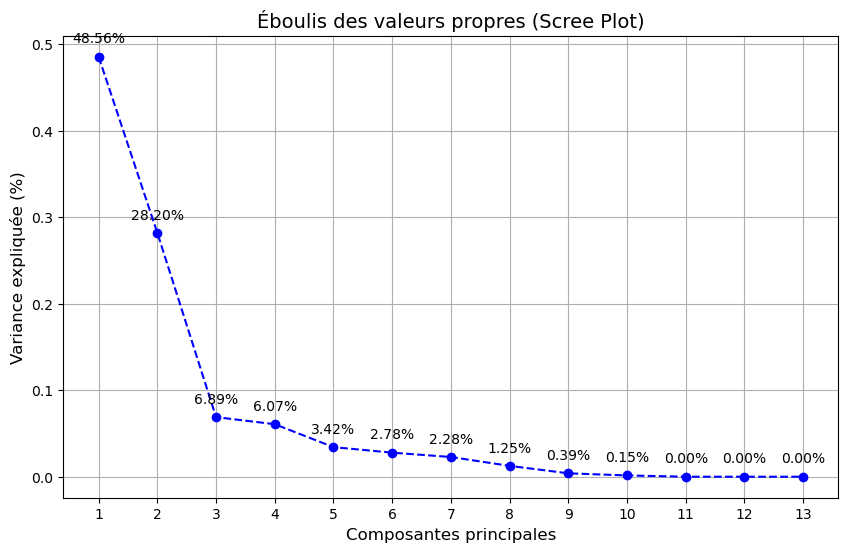

In [22]:
# Normalisation des données avant l'ACP
scaler = MinMaxScaler()
acp_scaled = scaler.fit_transform(df_acp.select_dtypes(include=['float64', 'int64']))

# Appliquer l'ACP
pca = PCA()
pca.fit(acp_scaled)

# Calcul des valeurs propres (variance expliquée)
explained_variance = pca.explained_variance_ratio_

# Tracer l'éboulis de valeurs propres
plt.figure(figsize=(10, 6))
plt.plot(range(1, len(explained_variance) + 1), explained_variance, marker='o', linestyle='--', color='b')
plt.title("Éboulis des valeurs propres (Scree Plot)", fontsize=14)
plt.xlabel("Composantes principales", fontsize=12)
plt.ylabel("Variance expliquée (%)", fontsize=12)
plt.xticks(range(1, len(explained_variance) + 1))
plt.grid(True)

# Ajouter des annotations pour chaque point
for i, var in enumerate(explained_variance):
    plt.annotate(f"{var:.2%}", (i + 1, var), textcoords="offset points", xytext=(0, 10), ha='center')

plt.show()


# Composantes principales

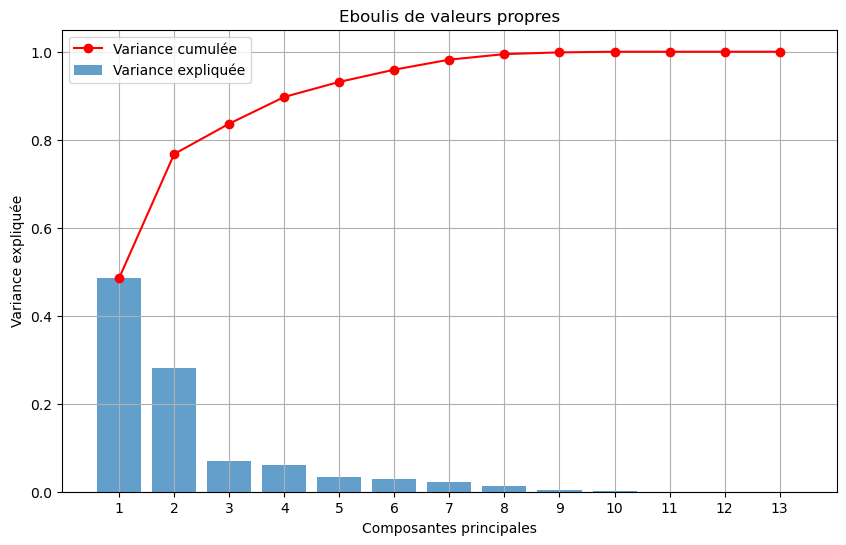

In [23]:
# Calcul de l'ACP sur toutes les composantes
pca_= PCA()
pca.fit(acp_scaled)

# Récupérer la variance expliquée pour toutes les composantes
explained_variance = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)
components = np.arange(1, len(explained_variance) + 1)

plt.figure(figsize=(10,6))
plt.bar(components, explained_variance, alpha=0.7, label='Variance expliquée')
plt.plot(components, cumulative_variance, color='red', marker='o', label='Variance cumulée')
plt.xlabel("Composantes principales")
plt.ylabel("Variance expliquée")
plt.title("Eboulis de valeurs propres")
plt.xticks(components)
plt.legend()
plt.grid(True)
plt.show()

In [24]:
# Trouver le nombre de composantes nécessaires pour expliquer 80 % de la variance
n_components = np.argmax(cumulative_variance >= 0.8) + 1
print(f"Nombre de composantes principales nécessaires pour expliquer 80 % de la variance : {n_components}")

Nombre de composantes principales nécessaires pour expliquer 80 % de la variance : 3


In [25]:
# Réduire les données à ces composantes principales
pca = PCA(n_components=n_components)
principal_components = pca.fit_transform(acp_scaled)

# Créer un DataFrame pour les composantes principales
columns = [f"F{i+1}" for i in range(principal_components.shape[1])]
principal_df = pd.DataFrame(principal_components, columns=columns)

# Obtenir les coefficients des composantes principales
loadings = pd.DataFrame(pca.components_, columns=df_acp.select_dtypes(include=['float64', 'int64']).columns, index=columns)

# Afficher les coefficients
print("Coefficients des composantes principales :")
loadings

Coefficients des composantes principales :


,Alimentation pour touristes,Disponibilité alimentaire (Kcal),Disponibilité intérieure,Exportations,Importations,Nourriture,Pertes,Production,Disponibilité alimentaire - Autres (Kcal),Importations Autres - quantité,Population totale,PIB par habitant,Stabilité politique
F1,0.012895,0.357645,0.376361,0.170888,0.284653,0.374682,0.006041,0.402159,0.311999,0.306377,0.345680,-0.003165,-0.084707
F2,0.025699,0.024020,0.023864,0.035657,0.055148,0.023451,-0.010494,0.027378,0.028425,0.064009,-0.025336,0.373824,0.920424
F3,-0.032881,-0.001514,0.055829,0.497486,-0.224487,0.050760,0.002423,0.160168,-0.136049,-0.146124,-0.173588,0.716510,-0.293762


# Correlations entre les facteurs et les indicateurs initiaux 

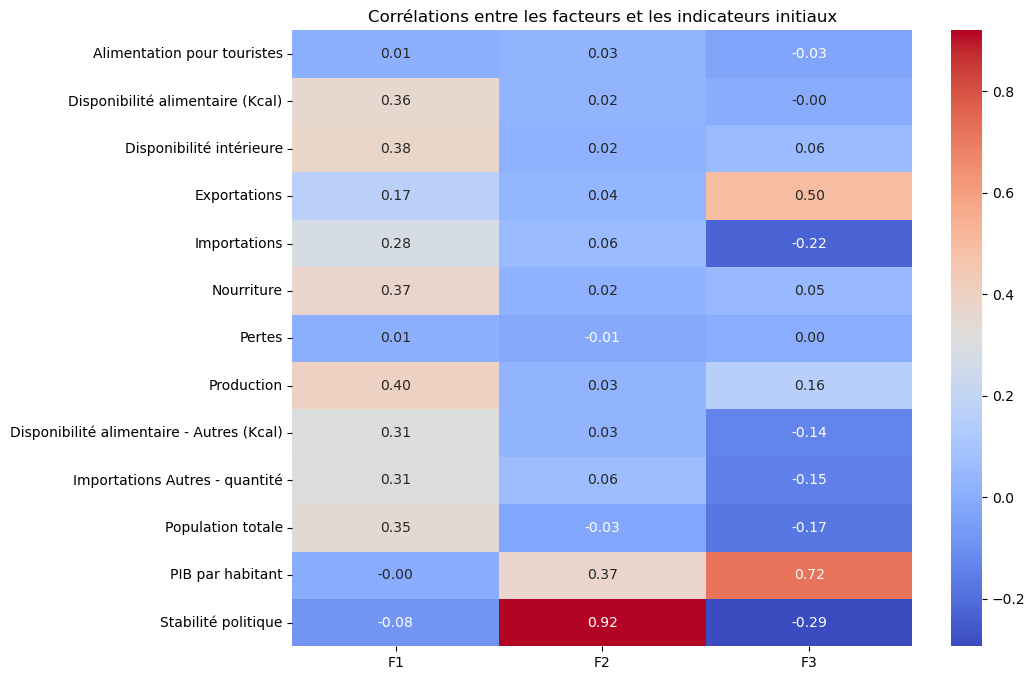

In [26]:
# Calcul des corrélations entre les facteurs et les indicateurs initiaux
correlations = pd.DataFrame(pca.components_.T, 
                            columns=[f"F{i+1}" for i in range(pca.n_components_)], 
                            index=df_acp.select_dtypes(include=['float64', 'int64']).columns)

# Visualisation sous forme de heatmap 
plt.figure(figsize=(10, 8))
sns.heatmap(correlations, annot=True, cmap="coolwarm", fmt=".2f", cbar=True)
plt.title("Corrélations entre les facteurs et les indicateurs initiaux")
plt.show()

+ F1 : Production, Nourriture et Disponibilité alimentaire
+ F2 : Stabilité politique et PIB par habitant
+ F3 : PIB par habitant et Exportations

# Cercle de correlations 

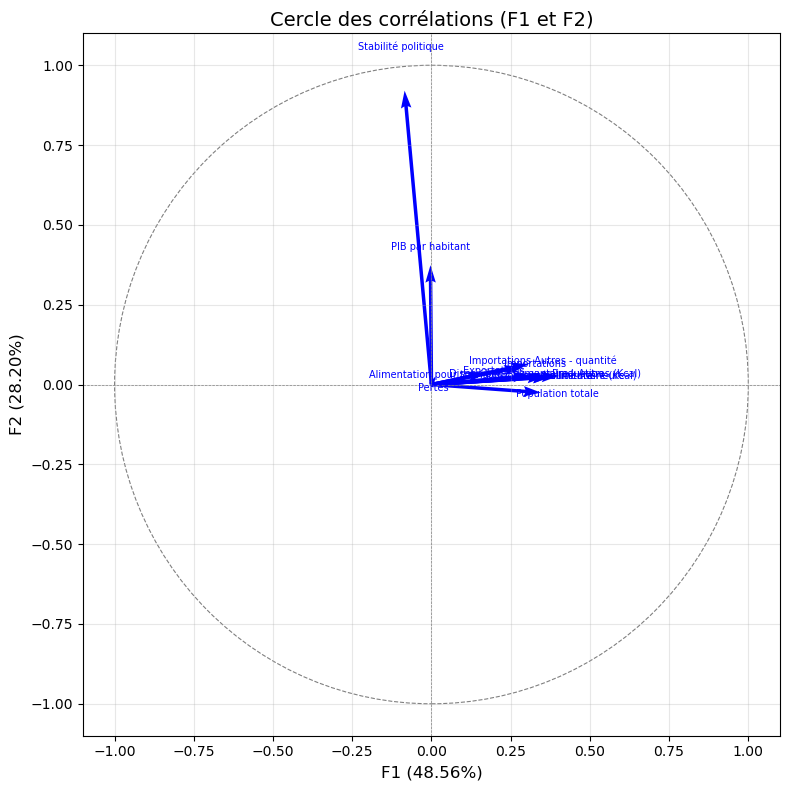

In [27]:
# Obtenir les loadings
loadings = pca.components_.T

# Définir la paire correspondant à F1 et F2
(i, j), (label_i, label_j) = ((0, 1), ("F1", "F2"))

# Créer la figure
fig, ax = plt.subplots(figsize=(8, 8))

# Lignes de repère
ax.axhline(0, color='grey', linestyle='--', linewidth=0.5)
ax.axvline(0, color='grey', linestyle='--', linewidth=0.5)

# Tracer les flèches pour chaque variable et afficher le texte avec clip_on=False
for k, var in enumerate(df_acp.select_dtypes(include=['float64', 'int64']).columns):
    ax.quiver(0, 0, loadings[k, i], loadings[k, j],
              angles='xy', scale_units='xy', scale=1, color='b', width=0.005)
    ax.text(loadings[k, i]*1.15, loadings[k, j]*1.15, var,
            color='b', ha='center', va='center', fontsize=7, clip_on=False)

# Tracer un cercle de rayon 1
circle = plt.Circle((0, 0), 1, color='grey', fill=False, linestyle='--', linewidth=0.8)
ax.add_artist(circle)

# Titres et axes
ax.set_title(f"Cercle des corrélations ({label_i} et {label_j})", fontsize=14)
ax.set_xlabel(f"{label_i} ({pca.explained_variance_ratio_[i]*100:.2f}%)", fontsize=12)
ax.set_ylabel(f"{label_j} ({pca.explained_variance_ratio_[j]*100:.2f}%)", fontsize=12)
ax.set_xlim(-1.1, 1.1)
ax.set_ylim(-1.1, 1.1)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

+ Le cercle de corrélation confirme notre constat dans le heatmap ci-dessus.

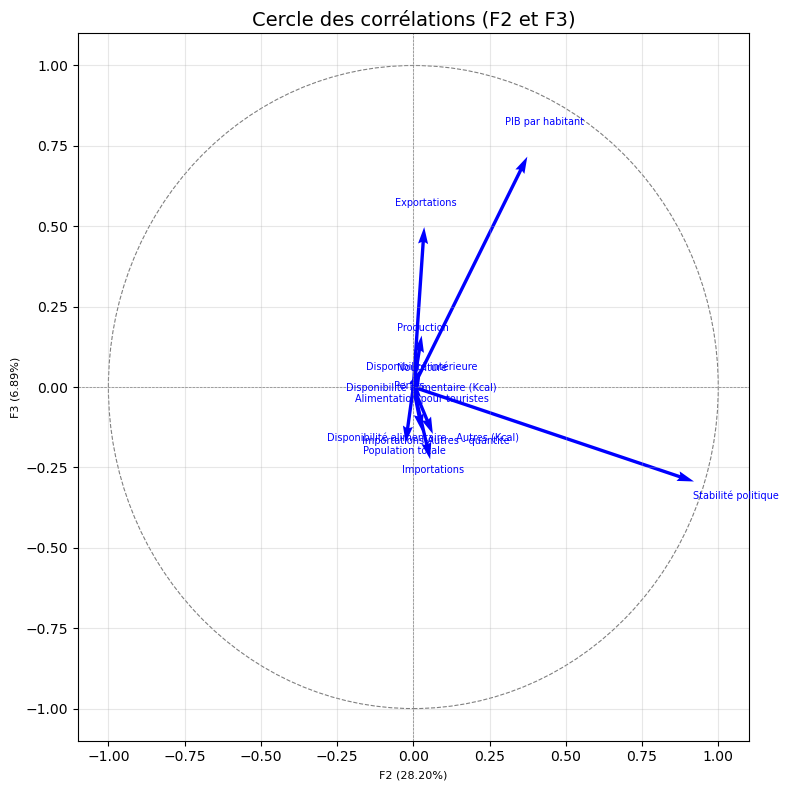

In [28]:
# Obtenir les loadings
loadings = pca.components_.T

# Définir la paire correspondant à F1 et F2
(i, j), (label_i, label_j) = ((1, 2), ("F2", "F3"))

# Créer la figure
fig, ax = plt.subplots(figsize=(8, 8))

# Lignes de repère
ax.axhline(0, color='grey', linestyle='--', linewidth=0.5)
ax.axvline(0, color='grey', linestyle='--', linewidth=0.5)

# Tracer les flèches pour chaque variable et afficher le texte avec clip_on=False
for k, var in enumerate(df_acp.select_dtypes(include=['float64', 'int64']).columns):
    ax.quiver(0, 0, loadings[k, i], loadings[k, j],
              angles='xy', scale_units='xy', scale=1, color='b', width=0.005)
    ax.text(loadings[k, i]*1.15, loadings[k, j]*1.15, var,
            color='b', ha='center', va='center', fontsize=7, clip_on=False)

# Tracer un cercle de rayon 1
circle = plt.Circle((0, 0), 1, color='grey', fill=False, linestyle='--', linewidth=0.8)
ax.add_artist(circle)

# Titres et axes
ax.set_title(f"Cercle des corrélations ({label_i} et {label_j})", fontsize=14)
ax.set_xlabel(f"{label_i} ({pca.explained_variance_ratio_[i]*100:.2f}%)", fontsize=8)
ax.set_ylabel(f"{label_j} ({pca.explained_variance_ratio_[j]*100:.2f}%)", fontsize=8)
ax.set_xlim(-1.1, 1.1)
ax.set_ylim(-1.1, 1.1)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

+ Le cercle de corrélation confirme notre constat dans le heatmap ci-dessus.

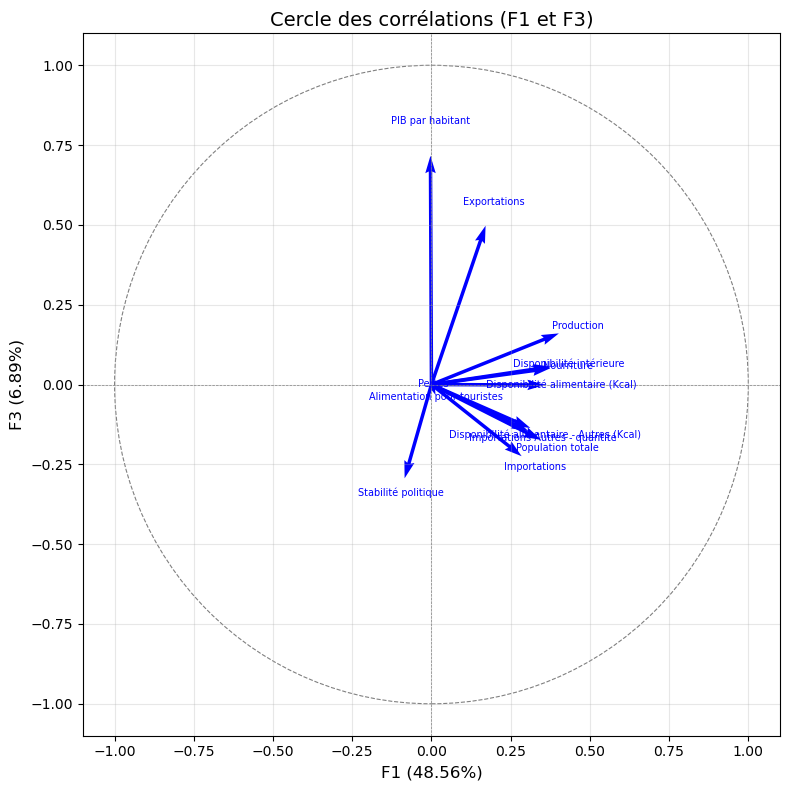

In [29]:
# Obtenir les loadings
loadings = pca.components_.T

# Définir la paire correspondant à F1 et F2
(i, j), (label_i, label_j) = ((0, 2), ("F1", "F3"))

# Créer la figure
fig, ax = plt.subplots(figsize=(8, 8))

# Lignes de repère
ax.axhline(0, color='grey', linestyle='--', linewidth=0.5)
ax.axvline(0, color='grey', linestyle='--', linewidth=0.5)

# Tracer les flèches pour chaque variable et afficher le texte avec clip_on=False
for k, var in enumerate(df_acp.select_dtypes(include=['float64', 'int64']).columns):
    ax.quiver(0, 0, loadings[k, i], loadings[k, j],
              angles='xy', scale_units='xy', scale=1, color='b', width=0.005)
    ax.text(loadings[k, i]*1.15, loadings[k, j]*1.15, var,
            color='b', ha='center', va='center', fontsize=7, clip_on=False)

# Tracer un cercle de rayon 1
circle = plt.Circle((0, 0), 1, color='grey', fill=False, linestyle='--', linewidth=0.8)
ax.add_artist(circle)

# Titres et axes
ax.set_title(f"Cercle des corrélations ({label_i} et {label_j})", fontsize=14)
ax.set_xlabel(f"{label_i} ({pca.explained_variance_ratio_[i]*100:.2f}%)", fontsize=12)
ax.set_ylabel(f"{label_j} ({pca.explained_variance_ratio_[j]*100:.2f}%)", fontsize=12)
ax.set_xlim(-1.1, 1.1)
ax.set_ylim(-1.1, 1.1)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

+ Le cercle de corrélation confirme notre constat dans le heatmap ci-dessus.

# Projections des pays sur le plan factoriel

Pour la projection des pays sur le plan factoriel, nous allons utiliser le clustering CAH parce qu'il y a moins de pays isolés.

In [30]:
# Projection sur le plan factoriel F1 et F2
df_plot = principal_df.copy()
df_plot["Zone"] = df_cah["Zone"]
df_plot["Cluster"] = df_cah["Cluster"].astype(str)

fig = px.scatter(
    df_plot, 
    x="F1", 
    y="F2", 
    color="Cluster",
    color_discrete_sequence=px.colors.qualitative.Vivid,
    hover_data={"F1": False, "F2": False, "Zone": True}, 
    labels={
        "F1": f"F1 ({pca.explained_variance_ratio_[0]*100:.2f}%)",
        "F2": f"F2 ({pca.explained_variance_ratio_[1]*100:.2f}%)"
    },
    title="Projection des pays sur le plan factoriel (F1 & F2)",
    width=800,
    height=700
)


fig.update_layout(
    title={
        'font': {'size': 18},
        'x': 0.5,           # Centre le titre horizontalement
        'xanchor': 'center'
    }
)

fig.show()

+ Cette projection confirme les caractéristiques des clusters.

In [31]:
# Projection sur le plan factoriel F2 et F3
df_plot = principal_df.copy()
df_plot["Zone"] = df_cah["Zone"]
df_plot["Cluster"] = df_cah["Cluster"].astype(str)

fig = px.scatter(
    df_plot, 
    x="F2", 
    y="F3", 
    color="Cluster",
    color_discrete_sequence=px.colors.qualitative.Vivid,
    hover_data={"F2": False, "F3": False, "Zone": True}, 
    labels={
        "F2": f"F2 ({pca.explained_variance_ratio_[1]*100:.2f}%)",
        "F3": f"F3 ({pca.explained_variance_ratio_[2]*100:.2f}%)"
    },
    title="Projection des pays sur le plan factoriel (F2 & F3)",
    width=800,
    height=700
)

fig.update_layout(
    title={
        'font': {'size': 18},
        'x': 0.5,           # Centre le titre horizontalement
        'xanchor': 'center'
    }
)

fig.show()

+ Cette projection confirme les caractéristiques des clusters.

In [32]:
# Projection sur le plan factoriel F1 et F3
df_plot = principal_df.copy()
df_plot["Zone"] = df_cah["Zone"]
df_plot["Cluster"] = df_cah["Cluster"].astype(str)

fig = px.scatter(
    df_plot, 
    x="F1", 
    y="F3", 
    color="Cluster",
    color_discrete_sequence=px.colors.qualitative.Vivid,
    hover_data={"F1": False, "F3": False, "Zone": True}, 
    labels={
        "F1": f"F1 ({pca.explained_variance_ratio_[0]*100:.2f}%)",
        "F3": f"F3 ({pca.explained_variance_ratio_[2]*100:.2f}%)"
    },
    title="Projection des pays sur le plan factoriel (F1 & F3)",
    width=800,
    height=700
)


fig.update_layout(
    title={
        'font': {'size': 18},
        'x': 0.5,           # Centre le titre horizontalement
        'xanchor': 'center'
    }
)

fig.show()

+ Cette projection confirme les caractéristiques des clusters.

<div style="background-color: RGB(0,150,250);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 3 - Conclusion</h2>
</div>

In [33]:
# Croiser le cluster 1 et cluster 4 dans df_cah et df_kmeans
# Extraire les pays du cluster 1 dans df_cah (CAH)
pays_cluster1_cah = set(df_cah[df_cah['Cluster'] == 1]['Zone'])

# Extraire les pays du cluster 1 dans df_kmeans (KMeans)
pays_cluster4_kmeans = set(df_kmeans[df_kmeans['Cluster'] ==4]['Zone'])

# Identifier l'intersection (les pays communs aux deux clusters)
pays_communs = pays_cluster1_cah.intersection(pays_cluster4_kmeans)

print("Pays en commun entre CAH Cluster 1 et K-Means Cluster 4 :")
print(", ".join(pays_communs))


Pays en commun entre CAH Cluster 1 et K-Means Cluster 4 :
Japon, République de Corée, Royaume-Uni de Grande-Bretagne et d'Irlande du Nord, Viet Nam, Italie, Allemagne, Argentine, Canada, Espagne, Pologne


En résumé, la liste des pays cibles a été établie ci-dessus. Il serait pertinent de débuter par des marchés à proximité de France, tels que l'Espagne, l'Italie et l'Allemagne, afin d'évaluer la faisabilité logistique et la conformité réglementaire de l'exportation de poulets.